# HW3：Fashion-MNIST 服飾影像分類

本作業使用 Fashion-MNIST 灰階影像建立一個多層全連接神經網路（DNN），辨識 10 種服飾。模型使用 `categorical_crossentropy` 損失函數與 Adam 優化器，並以訓練資料的 20% 作為驗證資料。

## 1. 資料預處理

Fashion-MNIST 每張圖片大小為 `28 x 28`，共有 10 個類別。像素值先除以 255 正規化到 `[0, 1]`，標籤則轉為 one-hot 向量，才能搭配多分類的 `categorical_crossentropy`。

In [301]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
print('訓練資料原始 shape:', x_train.shape, y_train.shape)
print('測試資料原始 shape:', x_test.shape, y_test.shape)

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train_onehot = keras.utils.to_categorical(y_train, 10)
y_test_onehot = keras.utils.to_categorical(y_test, 10)

print('正規化後訓練影像 shape:', x_train.shape)
print('正規化後測試影像 shape:', x_test.shape)
print('one-hot 訓練標籤 shape:', y_train_onehot.shape)
print('one-hot 測試標籤 shape:', y_test_onehot.shape)

訓練資料原始 shape: (60000, 28, 28) (60000,)
測試資料原始 shape: (10000, 28, 28) (10000,)
正規化後訓練影像 shape: (60000, 28, 28)
正規化後測試影像 shape: (10000, 28, 28)
one-hot 訓練標籤 shape: (60000, 10)
one-hot 測試標籤 shape: (10000, 10)


中文字形

In [302]:
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

# Windows 中文字型
font_candidates = [
    r"C:\Windows\Fonts\msjh.ttc",    # Microsoft JhengHei
    r"C:\Windows\Fonts\msjhl.ttc",   # Microsoft JhengHei Light
    r"C:\Windows\Fonts\mingliu.ttc", # 細明體
]

font_path = next(
    (path for path in font_candidates if os.path.exists(path)),
    None
)

if font_path is None:
    raise FileNotFoundError(
        "找不到中文字型，請確認 C:\\Windows\\Fonts 中是否有 msjh.ttc 或 mingliu.ttc"
    )

font_manager.fontManager.addfont(font_path)
rcParams["font.family"] = font_manager.FontProperties(
    fname=font_path
).get_name()

# 避免負號顯示成方框
rcParams["axes.unicode_minus"] = False

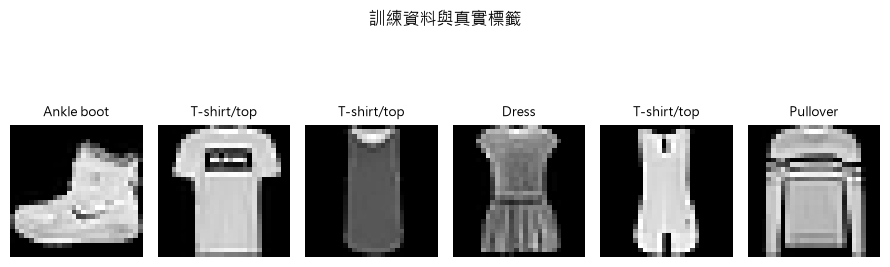

In [303]:
plt.figure(figsize=(9, 3))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis('off')
plt.suptitle('訓練資料與真實標籤', y=1.05)
plt.tight_layout()
plt.show()

## 2. 建立神經網路模型


In [304]:
model = keras.Sequential([
    layers.Input(shape=(28, 28), name='image_input'),
    layers.Flatten(name='flatten'),
    layers.Dense(1000, activation='relu', kernel_initializer='he_normal', name='hidden_1'),
    layers.BatchNormalization(name='batch_norm_1'),
    layers.Dropout(0.20, name='dropout_1'),
    layers.Dense(600, activation='relu', kernel_initializer='he_normal', name='hidden_2'),
    layers.BatchNormalization(name='batch_norm_2'),
    layers.Dropout(0.20, name='dropout_2'),
    layers.Dense(10, activation='softmax', name='output')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

print('DNN 可訓練參數總數:', model.count_params())

Model: "sequential_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 1000)           │       785,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 1000)           │         4,000 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 600)            │       600,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 600)            │         2,400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         6,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,398,010 (5.33 MB)

 Trainable params: 1,394,810 (5.32 MB)

 Non-trainable params: 3,200 (12.50 KB)

DNN 可訓練參數總數: 1398010


## 3. 訓練神經網路模型

`validation_split=0.2` 會從訓練資料切出 20% 作為驗證資料，這些資料不參與權重更新，只用來觀察模型對未參與訓練資料的表現。`batch_size=128` 表示每次用 128 張圖片計算梯度並更新一次權重；每一 epoch 約有 `48,000 / 128 ≈ 375` 次更新。

In [305]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1
    )
]

history = model.fit(
    x_train,
    y_train_onehot,
    epochs=30,
    batch_size=600,
    validation_split=0.2,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8155 - loss: 0.5387 - val_accuracy: 0.8045 - val_loss: 0.5839 - learning_rate: 0.0010
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8633 - loss: 0.3733 - val_accuracy: 0.8452 - val_loss: 0.4467 - learning_rate: 0.0010
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8797 - loss: 0.3253 - val_accuracy: 0.8646 - val_loss: 0.3790 - learning_rate: 0.0010
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8890 - loss: 0.3001 - val_accuracy: 0.8712 - val_loss: 0.3599 - learning_rate: 0.0010
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8943 - loss: 0.2831 - val_accuracy: 0.8503 - val_loss: 0.4164 - learning_rate: 0.0010
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8982 - loss: 0.2718 - val_accuracy: 0.8707 - val_loss: 0.3568 - learning_rate: 0.0010
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9018 - loss: 0.2586 - val_acc

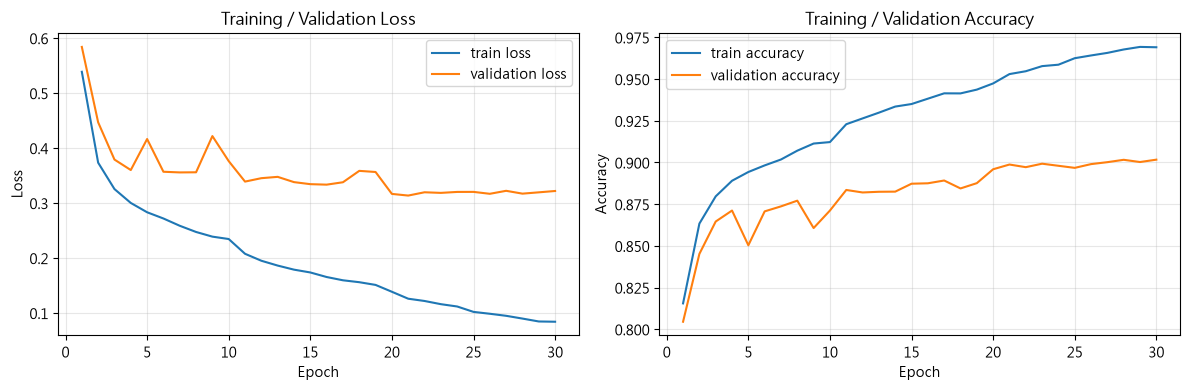

驗證集最佳 epoch: 30
最佳驗證準確率: 0.9017
判斷 overfitting：若 training accuracy 持續上升但 validation accuracy 下降，
或 validation loss 持續上升，代表出現 overfitting；本模型加入 Dropout 以減少此現象。


In [306]:
history_dict = history.history
epochs = range(1, len(history_dict['loss']) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_dict['loss'], label='train loss')
plt.plot(epochs, history_dict['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training / Validation Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_dict['accuracy'], label='train accuracy')
plt.plot(epochs, history_dict['val_accuracy'], label='validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training / Validation Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_epoch = int(np.argmax(history_dict['val_accuracy'])) + 1
print(f'驗證集最佳 epoch: {best_epoch}')
print(f'最佳驗證準確率: {max(history_dict["val_accuracy"]):.4f}')
print('判斷 overfitting：若 training accuracy 持續上升但 validation accuracy 下降，')
print('或 validation loss 持續上升，代表出現 overfitting；本模型加入 Dropout 以減少此現象。')

## 4. 使用全部測試資料評估準確率

In [307]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test_onehot, batch_size=500, verbose=1
)
print(f'測試資料 loss: {test_loss:.4f}')
print(f'測試資料 accuracy: {test_accuracy:.4%}')

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9008 - loss: 0.3538
測試資料 loss: 0.3538
測試資料 accuracy: 90.0800%


## 5. 使用全部測試資料進行預測

`model.predict` 輸出每個類別的機率陣列；使用 `argmax(axis=1)` 取機率最大的索引，再用 `class_names` 轉成服飾名稱，而不是直接顯示類別編號或機率。

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
預測資料 shape: (10000, 10)
前 10 筆預測與真實標籤：
 0: 預測 = Ankle boot   | 真實 = Ankle boot
 1: 預測 = Pullover     | 真實 = Pullover
 2: 預測 = Trouser      | 真實 = Trouser
 3: 預測 = Trouser      | 真實 = Trouser
 4: 預測 = Shirt        | 真實 = Shirt
 5: 預測 = Trouser      | 真實 = Trouser
 6: 預測 = Coat         | 真實 = Coat
 7: 預測 = Shirt        | 真實 = Shirt
 8: 預測 = Sandal       | 真實 = Sandal
 9: 預測 = Sneaker      | 真實 = Sneaker


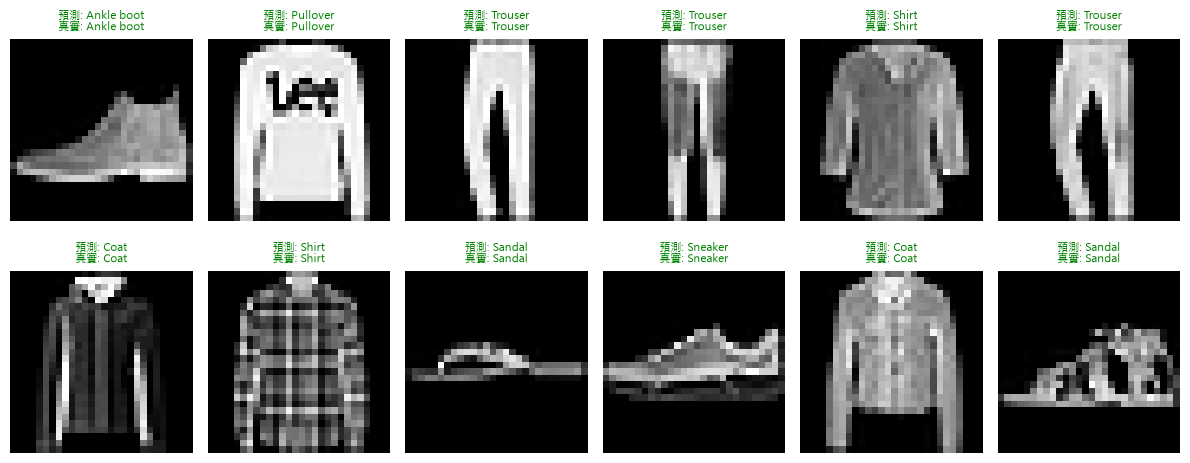

In [308]:
test_probabilities = model.predict(x_test, batch_size=128, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1)

print('預測資料 shape:', test_probabilities.shape)
print('前 10 筆預測與真實標籤：')
for i in range(10):
    print(f'{i:2d}: 預測 = {class_names[y_pred[i]]:12s} | 真實 = {class_names[y_test[i]]}')

plt.figure(figsize=(12, 5))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    plt.title(f'預測: {class_names[y_pred[i]]}\n真實: {class_names[y_test[i]]}', color=color, fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 6. 混淆矩陣（Confusion Matrix）

混淆矩陣的列代表真實類別，欄代表預測類別；對角線上的數值越大，表示該類別辨識正確的樣本越多。

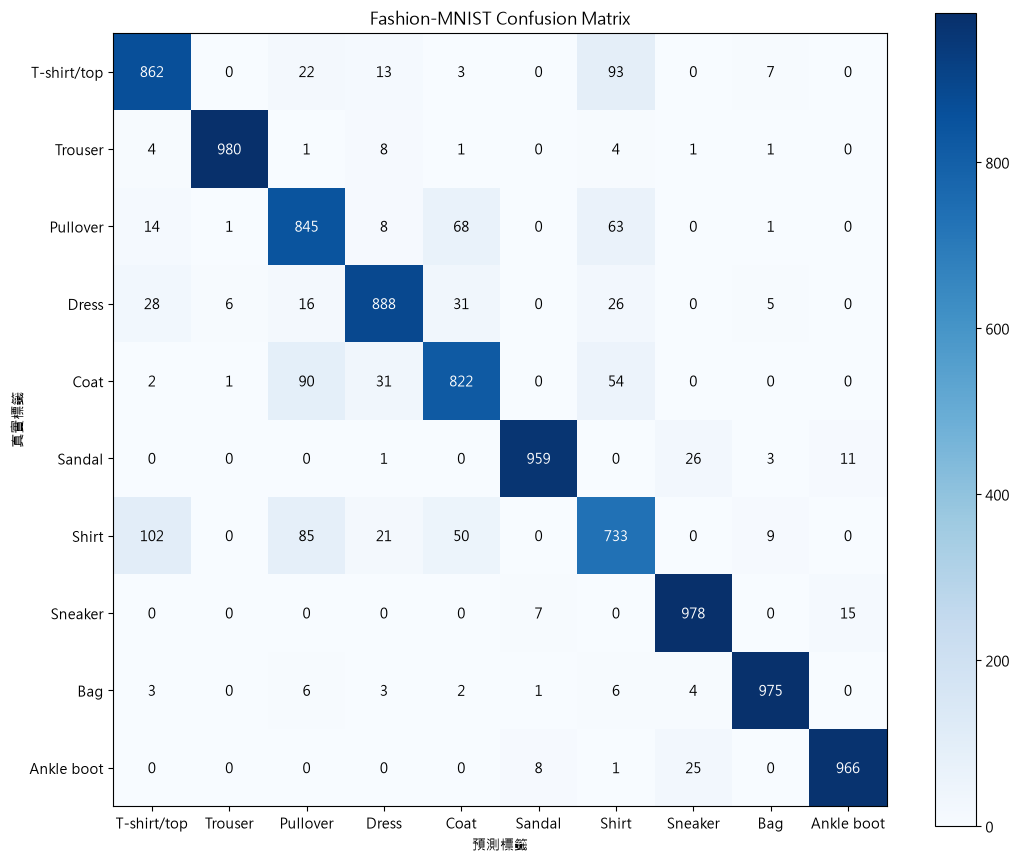

混淆矩陣（列=真實，欄=預測）：
[[862   0  22  13   3   0  93   0   7   0]
 [  4 980   1   8   1   0   4   1   1   0]
 [ 14   1 845   8  68   0  63   0   1   0]
 [ 28   6  16 888  31   0  26   0   5   0]
 [  2   1  90  31 822   0  54   0   0   0]
 [  0   0   0   1   0 959   0  26   3  11]
 [102   0  85  21  50   0 733   0   9   0]
 [  0   0   0   0   0   7   0 978   0  15]
 [  3   0   6   3   2   1   6   4 975   0]
 [  0   0   0   0   0   8   1  25   0 966]]


In [309]:
cm = tf.math.confusion_matrix(y_test, y_pred, num_classes=10).numpy()
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(cm, interpolation='nearest', cmap='Blues')
fig.colorbar(image, ax=ax)
ax.set(xticks=np.arange(10), yticks=np.arange(10),
       xticklabels=class_names, yticklabels=class_names)
threshold = cm.max() / 2.0
for row in range(cm.shape[0]):
    for column in range(cm.shape[1]):
        ax.text(column, row, format(cm[row, column], 'd'),
                ha='center', va='center',
                color='white' if cm[row, column] > threshold else 'black')
ax.set_title('Fashion-MNIST Confusion Matrix')
ax.set_xlabel('預測標籤')
ax.set_ylabel('真實標籤')
plt.tight_layout()
plt.show()

print('混淆矩陣（列=真實，欄=預測）：')
print(cm)

## 7. 儲存完整模型

以下會儲存模型架構、權重與 optimizer 狀態，之後可直接載入繼續訓練或進行預測。

In [310]:
model_path = 'fashion_mnist_dnn_hw3.keras'
model.save(model_path)
print(f'完整模型已儲存：{model_path}')

# 驗證模型可以重新載入，並保留相同的模型資訊。
loaded_model = keras.models.load_model(model_path)
print('重新載入後的參數總數:', loaded_model.count_params())
print('重新載入模型的測試 accuracy:', loaded_model.evaluate(x_test, y_test_onehot, verbose=0)[1])

完整模型已儲存：fashion_mnist_dnn_hw3.keras
重新載入後的參數總數: 1398010
重新載入模型的測試 accuracy: 0.9007999897003174
